# Assignment 4 - Autoencoder anomaly detection (MNIST)
**Offline version** - runs without internet.
Needs `mnist.npz` in the same folder (see `00_download_once.ipynb`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

tf.random.set_seed(42)
np.random.seed(42)

print("All libraries imported successfully!")
print("TensorFlow:", tf.__version__)

All libraries imported successfully!
TensorFlow: 2.22.0-rc0


In [2]:
def load_mnist(path="mnist.npz"):
    for p in (path, os.path.expanduser("~/.keras/datasets/mnist.npz")):
        if os.path.exists(p):
            with np.load(p, allow_pickle=True) as f:
                return (f["x_train"], f["y_train"]), (f["x_test"], f["y_test"])

    raise FileNotFoundError("mnist.npz not found!")

(x_train, y_train), (x_test, y_test) = load_mnist()

print("Dataset loaded successfully!")
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Dataset loaded successfully!
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


In [3]:
x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test.reshape(-1, 784).astype("float32") / 255.0

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 784)
Testing shape: (10000, 784)


In [4]:
NORMAL = 1

# Select only normal images for training
x_normal = x_train[y_train == NORMAL]

rng = np.random.default_rng(42)

# Select normal test images
norm_idx = np.where(y_test == NORMAL)[0]

# Select 150 anomalous images
anom_idx = rng.choice(
    np.where(y_test != NORMAL)[0],
    size=150,
    replace=False
)

# Combine normal and anomalous test images
idx = np.concatenate([norm_idx, anom_idx])
rng.shuffle(idx)

x_eval = x_test[idx]

# 0 = Normal, 1 = Anomaly
y_eval = (y_test[idx] != NORMAL).astype(int)

print("Normal training samples:", x_normal.shape[0])
print("Total test samples:", len(idx))
print("Normal test samples:", np.sum(y_eval == 0))
print("Anomaly test samples:", np.sum(y_eval == 1))

Normal training samples: 6742
Total test samples: 1285
Normal test samples: 1135
Anomaly test samples: 150


In [5]:
# Encoder
inp = keras.Input(shape=(784,))

e = layers.Dense(128, activation="relu")(inp)
e = layers.Dense(64, activation="relu")(e)

# Latent representation
code = layers.Dense(
    16,
    activation="relu",
    name="latent"
)(e)

# Decoder
d = layers.Dense(64, activation="relu")(code)
d = layers.Dense(128, activation="relu")(d)

out = layers.Dense(784, activation="sigmoid")(d)

# Complete Autoencoder
autoencoder = keras.Model(
    inp,
    out,
    name="MNIST_Autoencoder"
)

autoencoder.summary()

Model: "MNIST_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ latent (Dense)                       │ (None, 16)                  │           1,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 220,320 (860.62 KB)

 Trainable params: 220,320 (860.62 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
autoencoder.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

print("Autoencoder compiled successfully!")

Autoencoder compiled successfully!


In [7]:
history = autoencoder.fit(
    x_normal,
    x_normal,
    epochs=30,
    batch_size=128,
    validation_split=0.1,
    shuffle=True,
    verbose=2
)

Epoch 1/30
48/48 - 2s - 45ms/step - loss: 0.0909 - mae: 0.1995 - val_loss: 0.0289 - val_mae: 0.0564
Epoch 2/30
48/48 - 0s - 7ms/step - loss: 0.0300 - mae: 0.0581 - val_loss: 0.0247 - val_mae: 0.0526
Epoch 3/30
48/48 - 1s - 14ms/step - loss: 0.0218 - mae: 0.0437 - val_loss: 0.0178 - val_mae: 0.0375
Epoch 4/30
48/48 - 0s - 8ms/step - loss: 0.0180 - mae: 0.0368 - val_loss: 0.0151 - val_mae: 0.0333
Epoch 5/30
48/48 - 0s - 8ms/step - loss: 0.0159 - mae: 0.0341 - val_loss: 0.0138 - val_mae: 0.0323
Epoch 6/30
48/48 - 0s - 8ms/step - loss: 0.0144 - mae: 0.0333 - val_loss: 0.0127 - val_mae: 0.0324
Epoch 7/30
48/48 - 0s - 8ms/step - loss: 0.0127 - mae: 0.0324 - val_loss: 0.0111 - val_mae: 0.0302
Epoch 8/30
48/48 - 0s - 8ms/step - loss: 0.0109 - mae: 0.0300 - val_loss: 0.0092 - val_mae: 0.0271
Epoch 9/30
48/48 - 0s - 8ms/step - loss: 0.0093 - mae: 0.0271 - val_loss: 0.0077 - val_mae: 0.0243
Epoch 10/30
48/48 - 0s - 7ms/step - loss: 0.0077 - mae: 0.0234 - val_loss: 0.0067 - val_mae: 0.0212
Epoch 1

In [8]:
def rec_error(x):
    reconstructed = autoencoder.predict(x, verbose=0)
    return np.mean((x - reconstructed) ** 2, axis=1)

# Training reconstruction error
train_err = rec_error(x_normal)

# Calculate threshold
threshold = train_err.mean() + 2 * train_err.std()

# Testing reconstruction error
err = rec_error(x_eval)

# Predict anomalies
y_pred = (err > threshold).astype(int)

print("Reconstruction threshold:", round(threshold, 5))
print("Reconstruction error calculated successfully!")

Reconstruction threshold: 0.01026
Reconstruction error calculated successfully!


In [9]:
print("Threshold:", round(threshold, 5))

print(
    "Mean error - Normal:",
    round(err[y_eval == 0].mean(), 5)
)

print(
    "Mean error - Anomaly:",
    round(err[y_eval == 1].mean(), 5)
)

print("\nROC-AUC Score:")
print(round(roc_auc_score(y_eval, err), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_eval, y_pred, labels=[0, 1]))

print("\nClassification Report:")

print(
    classification_report(
        y_eval,
        y_pred,
        labels=[0, 1],
        target_names=["normal", "anomaly"],
        digits=4,
        zero_division=0
    )
)

Threshold: 0.01026
Mean error - Normal: 0.00329
Mean error - Anomaly: 0.07089

ROC-AUC Score:
0.9992

Confusion Matrix:
[[1090   45]
 [   0  150]]

Classification Report:
              precision    recall  f1-score   support

      normal     1.0000    0.9604    0.9798      1135
     anomaly     0.7692    1.0000    0.8696       150

    accuracy                         0.9650      1285
   macro avg     0.8846    0.9802    0.9247      1285
weighted avg     0.9731    0.9650    0.9669      1285



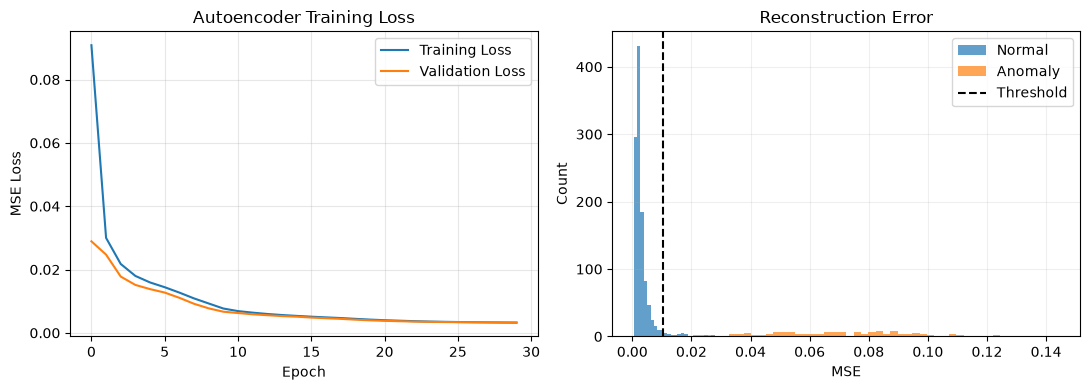

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Training loss
ax[0].plot(history.history["loss"], label="Training Loss")
ax[0].plot(history.history["val_loss"], label="Validation Loss")

ax[0].set_title("Autoencoder Training Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("MSE Loss")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Reconstruction error histogram
ax[1].hist(
    err[y_eval == 0],
    bins=50,
    alpha=0.7,
    label="Normal"
)

ax[1].hist(
    err[y_eval == 1],
    bins=50,
    alpha=0.7,
    label="Anomaly"
)

ax[1].axvline(
    threshold,
    color="black",
    linestyle="--",
    label="Threshold"
)

ax[1].set_title("Reconstruction Error")
ax[1].set_xlabel("MSE")
ax[1].set_ylabel("Count")
ax[1].legend()
ax[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig("a4_error.png", dpi=130)
plt.show()

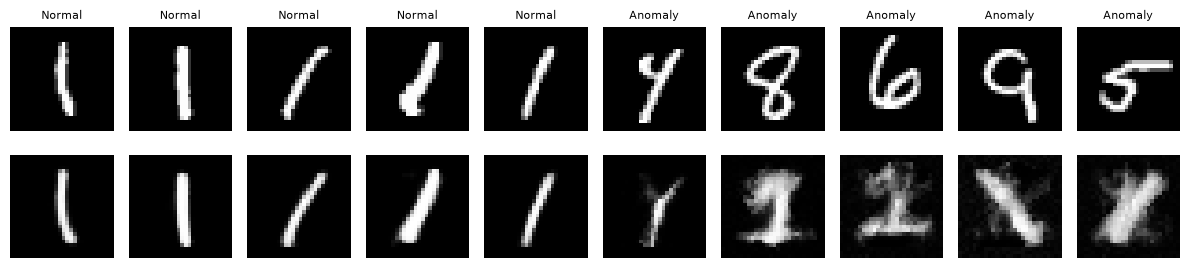

In [11]:
# Select five normal and five anomalous images
normal_samples = np.where(y_eval == 0)[0][:5]
anomaly_samples = np.where(y_eval == 1)[0][:5]

sel = list(normal_samples) + list(anomaly_samples)

# Reconstruct images
rec = autoencoder.predict(x_eval[sel], verbose=0)

fig, ax = plt.subplots(2, 10, figsize=(12, 3))

for i, k in enumerate(sel):

    # Original images
    ax[0, i].imshow(
        x_eval[k].reshape(28, 28),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax[0, i].axis("off")

    # Reconstructed images
    ax[1, i].imshow(
        rec[i].reshape(28, 28),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax[1, i].axis("off")

    ax[0, i].set_title(
        "Normal" if y_eval[k] == 0 else "Anomaly",
        fontsize=8
    )

ax[0, 0].set_ylabel("Original")
ax[1, 0].set_ylabel("Reconstructed")

plt.tight_layout()
plt.savefig("a4_recon.png", dpi=130)
plt.show()

In [12]:
print("Assignment 4 completed successfully!")

print("Normal digit:", NORMAL)
print("Anomaly digits: All other digits")

print("Threshold:", round(threshold, 5))

print("ROC-AUC:", round(roc_auc_score(y_eval, err), 4))

print("Graph 1 saved: a4_error.png")
print("Graph 2 saved: a4_recon.png")

Assignment 4 completed successfully!
Normal digit: 1
Anomaly digits: All other digits
Threshold: 0.01026
ROC-AUC: 0.9992
Graph 1 saved: a4_error.png
Graph 2 saved: a4_recon.png


In [13]:
autoencoder.save("mnist_autoencoder.keras")

print("Autoencoder model saved successfully!")

Autoencoder model saved successfully!
